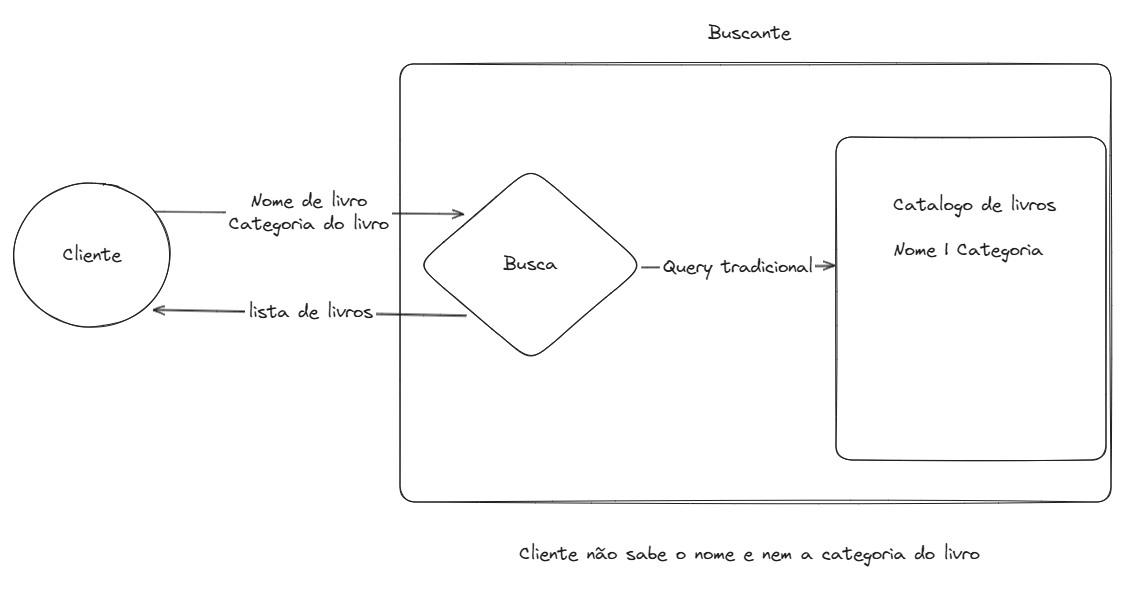

In [6]:
import os
import requests
import pandas as pd
from dotenv import load_dotenv

In [7]:
# Carrega as variáveis de ambiente do arquivo .env e api-key
load_dotenv()
key = os.environ.get("GROQ_API_KEY")

# Faz a requisição para a API da Groq para obter os modelos disponíveis

url = "https://api.groq.com/openai/v1/models"

headers = {
    "Authorization": f"Bearer {key}",
    "Content-Type": "application/json"
}

response = requests.get(url, headers=headers)
dados = response.json()["data"]

# Cria o DataFrame a partir da lista 'data'
df = pd.DataFrame(dados)

# Converte o timestamp Unix para data legível e ordena pelo ID do modelo
df["created"] = pd.to_datetime(df["created"], unit="s").dt.strftime("%Y-%m-%d")
df = df[["id", "owned_by", "context_window", "max_completion_tokens", "active", "created"]]
df = df.sort_values("id").reset_index(drop=True)

# No Jupyter,

df

,id,owned_by,context_window,max_completion_tokens,active,created
0,allam-2-7b,SDAIA,4096,4096,True,2025-01-23
1,canopylabs/orpheus-arabic-saudi,Canopy Labs,4000,50000,True,2025-12-16
2,canopylabs/orpheus-v1-english,Canopy Labs,4000,50000,True,2025-12-19
3,meta-llama/llama-prompt-guard-2-22m,Meta,512,512,True,2025-05-30
4,meta-llama/llama-prompt-guard-2-86m,Meta,512,512,True,2025-05-30
5,openai/gpt-oss-120b,OpenAI,131072,65536,True,2025-08-05
6,openai/gpt-oss-20b,OpenAI,131072,65536,True,2025-08-05
7,openai/gpt-oss-safeguard-20b,OpenAI,131072,65536,True,2025-10-29
8,qwen/qwen3.8-27b,Alibaba Cloud,131072,16384,True,2026-08-17
9,whisper-large-v3,OpenAI,448,448,True,2023-09-03


In [8]:
!pip install -q llama-index llama-index-llms-groq

In [9]:
from llama_index.llms.groq import Groq

llm = Groq(model="openai/gpt-oss-120b", api_key=key)


In [10]:
from llama_index.core.chat_engine import SimpleChatEngine

In [11]:
chat_engine = SimpleChatEngine.from_defaults(llm=llm)

In [12]:
chat_engine.chat_repl()

===== Entering Chat REPL =====
Type "exit" to exit.

Assistant: Hoje é **segunda‑feira, 23 de novembro de 2026**.



In [13]:
llm.complete("Consegue me ajudar com duvidas literarias ?")

CompletionResponse(text='Claro! 😊 Estou à disposição para esclarecer dúvidas sobre literatura: autores, obras, movimentos, técnicas de escrita, análise de textos, recomendações de leitura e muito mais. \n\nSobre o que você gostaria de conversar? \n\n- **Autor ou obra específica**  \n- **Movimento literário** (Romantismo, Modernismo, etc.)  \n- **Análise de personagens, temas ou símbolos**  \n- **Dicas de leitura**  \n- **Técnicas de escrita** (narrativa, poesia, roteiro)  \n\nFique à vontade para detalhar sua dúvida que eu ajudo da melhor forma possível!', additional_kwargs={'prompt_tokens': 81, 'completion_tokens': 186, 'total_tokens': 267}, raw=ChatCompletion(id='chatcmpl-8a409771-34c6-48de-9d45-7e259f2ca636', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='Claro! 😊 Estou à disposição para esclarecer dúvidas sobre literatura: autores, obras, movimentos, técnicas de escrita, análise de textos, recomendações de leitura e muito mais. 

In [14]:
resposta = llm.complete("Consegue me ajudar com duvidas literarias ?").text

In [15]:
print(resposta)

Claro! 😊 Estou à disposição para esclarecer dúvidas sobre literatura: autores, obras, movimentos, técnicas de escrita, análise de textos, recomendações de leitura e muito mais. Sobre o que você gostaria de conversar?


In [16]:
duvida_user = "Recomende livros de romance"

In [17]:
resposta = llm.complete(duvida_user).text
print(resposta)

Claro! Aqui vai uma lista variada de romances (ficção romântica) que agradam diferentes gostos, com breves sinopses para ajudar na escolha. Incluí obras clássicas, contemporâneas, brasileiras e traduções de autores internacionais.

---

## 1. **Clássicos imperdíveis**

| Título | Autor | Ano | Por que ler |
|--------|-------|-----|-------------|
| **Orgulho e Preconceito** | Jane Austen | 1813 | Uma das histórias de amor mais icônicas da literatura, combina humor, crítica social e personagens inesquecíveis. |
| **Jane Eyre** | Charlotte Brontë | 1847 | Romance gótico que mistura paixão, independência feminina e questões morais. |
| **Cem Anos de Solidão** | Gabriel García Márquez | 1967 | Embora seja mais um romance familiar, o amor permeia gerações em uma narrativa mágica e poética. |
| **O Morro dos Ventos Uivados** | Emily Brontë | 1847 | Amor obsessivo e tormentoso em meio a uma paisagem sombria da Inglaterra vitoriana. |

---

## 2. **Romances contemporâneos em língua portuguesa**